In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import kstest

from DataAnalysis import joint_distribution
from DataPreprocessing import smart_imputer

In [2]:
path = "/Users/zuzannasosnowska/.cache/kagglehub/datasets/krzysztofjamroz/apartment-prices-in-poland/versions/9/apartments_pl_2024_06.csv"

df = pd.read_csv(path)

In [3]:
df["price_per_m2"] = df["price"] / df["squareMeters"]

In [4]:
polish_cities_names = {'szczecin': 'Szczecin', 'gdynia': 'Gdynia', 'krakow': 'Kraków',  'poznan': 'Poznań', 'bialystok': 'Białystok',  'gdansk': 'Gdańsk', 'wroclaw': 'Wrocław', 'radom': 'Radom', 'rzeszow': 'Rzeszów', 'lodz': 'Łódź', 'katowice': 'Katowice', 'lublin': 'Lublin', 'czestochowa': 'Częstochowa', 'warszawa': 'Warszawa', 'bydgoszcz': 'Bydgoszcz'}

df['city'] = [polish_cities_names[city] for city in df['city']]

In [5]:
city_dataframes = {city: df[df["city"] == city] for city in df.city.unique()}
cities = df["city"].unique()

In [6]:
df = smart_imputer(df)[0]

/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/Semestr 7/Praca_inżynierska/functions.py:132: UserWarning: Kolumna "buildingMaterial" (kategoryczna) ma >40% braków → pomijam.
  warnings.warn(f'Kolumna "{column}" (kategoryczna) ma >40% braków → pomijam.')
/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/Semestr 7/Praca_inżynierska/functions.py:132: UserWarning: Kolumna "condition" (kategoryczna) ma >40% braków → pomijam.
  warnings.warn(f'Kolumna "{column}" (kategoryczna) ma >40% braków → pomijam.')


In [8]:
categorical_data = ['city', 'type', 'ownership', 'buildingMaterial', 'condition', 'hasParkingSpace', 'hasBalcony', 'hasElevator', 'hasSecurity', 'hasStorageRoom']

both_categorical_and_numeric = ['rooms', 'floor', 'floorCount']

numeric_data = ['squareMeters', 'buildYear', 'latitude', 'longitude', 'centreDistance', 'poiCount', 'schoolDistance', 'clinicDistance', 'postOfficeDistance', 'kindergartenDistance', 'restaurantDistance', 'collegeDistance', 'pharmacyDistance', 'price', 'price_per_m2']

df[categorical_data] = df[categorical_data].astype("category")

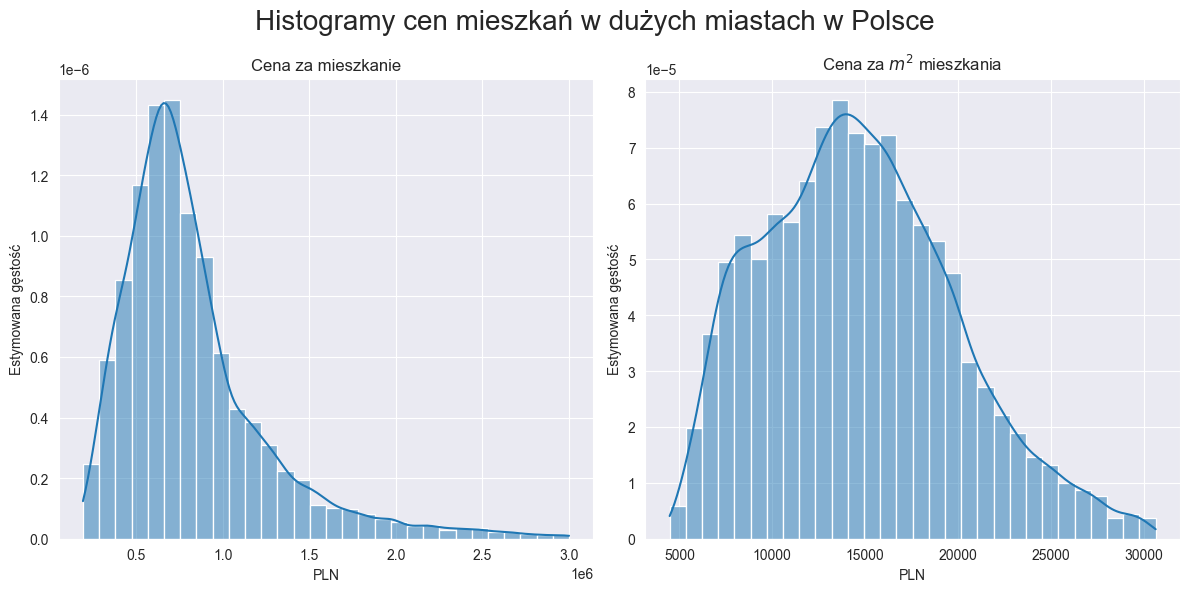

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle("Histogramy cen mieszkań w dużych miastach w Polsce", fontsize=20)
axes[0].set_title("Cena za mieszkanie")
axes[0].set_xlabel("PLN")
axes[0].set_ylabel("Estymowana gęstość")
sns.histplot(data=df, x="price", kde=True, stat="density", bins=30, ax=axes[0])

axes[1].set_title(r"Cena za $m^2$ mieszkania")
axes[1].set_xlabel("PLN")
axes[1].set_ylabel("Estymowana gęstość")
sns.histplot(data=df, x="price_per_m2", kde=True, stat="density", bins=30, ax=axes[1])

plt.tight_layout()
plt.show()

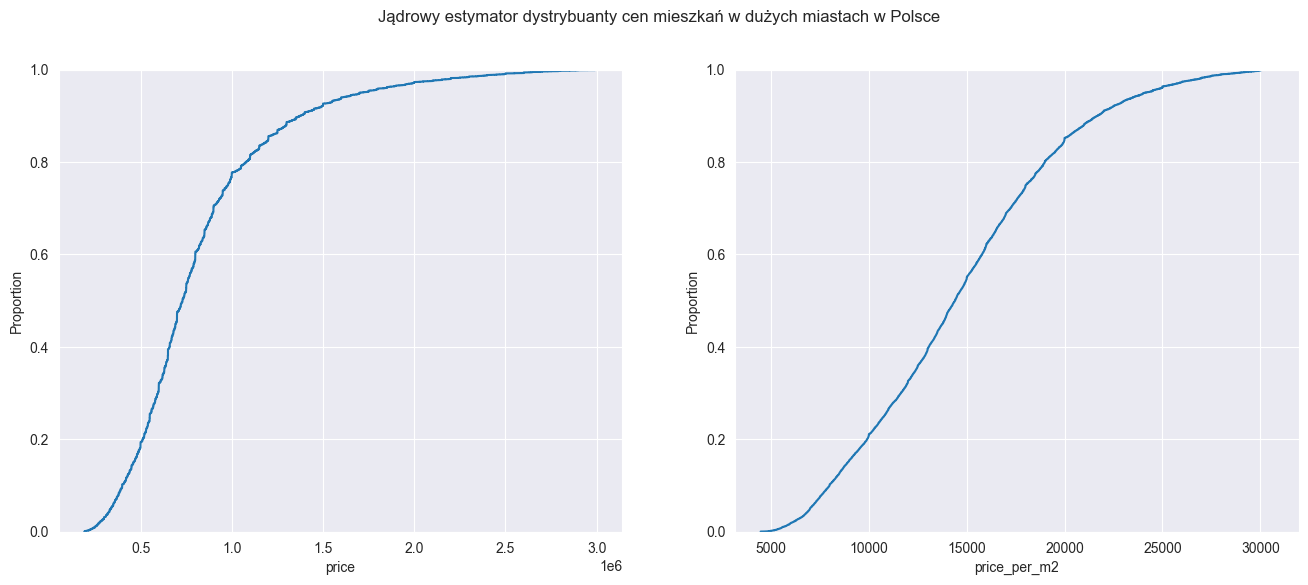

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16,6))

fig.suptitle("Jądrowy estymator dystrybuanty cen mieszkań w dużych miastach w Polsce")
sns.ecdfplot(df["price"], ax=axes[0])
sns.ecdfplot(df["price_per_m2"], ax=axes[1])
plt.show()

In [11]:
price = df["price"]
price_per_m2 = df["price_per_m2"]

price_per_m2_distributions_parameters = {"lognorm": stats.lognorm.fit(price_per_m2),
                 "norm": stats.norm.fit(price_per_m2),
                 "t": stats.t.fit(price_per_m2),
                 "gamma": stats.gamma.fit(price_per_m2),
                 "chi2": stats.chi2.fit(price_per_m2)
                 }

price_distributions_parameters = {"lognorm": stats.lognorm.fit(price),
                 "norm": stats.norm.fit(price),
                 "t": stats.t.fit(price),
                 "gamma": stats.gamma.fit(price),
                 "chi2": stats.chi2.fit(price)
                 }

print(price_per_m2_distributions_parameters["lognorm"])

(np.float64(0.21222901691378382), -9717.220385486422, np.float64(23895.179207205758))


In [12]:
def ks_test_dataframe(data, distributions_dict):
    ks_test_results = pd.DataFrame(columns=["Statystyka", "P-wartość"], index=distributions_dict.keys())

    for distribution, parameters in distributions_dict.items():
        test = kstest(data, distribution, parameters)
        ks_test_results.loc[distribution, "Statystyka"] = test.statistic
        ks_test_results.loc[distribution, "P-wartość"] = test.pvalue

    return ks_test_results


print("Wyniki testu Kołmogorowa-Smirnowa dla cen za m^2 mieszkania")
display(ks_test_dataframe(price_per_m2, price_per_m2_distributions_parameters))
print("Wyniki testu Kołmogorowa-Smirnowa dla cen mieszkań")
display(ks_test_dataframe(price, price_distributions_parameters))

# latex_table = pd.concat(
#     {'Cena': ks_test_dataframe(price, price_distributions_parameters),
#      'Cena za m^2': ks_test_dataframe(price_per_m2, price_per_m2_distributions_parameters)}, axis=1
# )
#
# print(latex_table.to_latex())

Wyniki testu Kołmogorowa-Smirnowa dla cen za m^2 mieszkania


,Statystyka,P-wartość
lognorm,0.02971,0.0
norm,0.030498,0.0
t,0.030533,0.0
gamma,0.028126,0.0
chi2,0.999329,0.0


Wyniki testu Kołmogorowa-Smirnowa dla cen mieszkań


,Statystyka,P-wartość
lognorm,0.040944,0.0
norm,0.142364,0.0
t,0.142367,0.0
gamma,0.141894,0.0
chi2,0.391269,0.0


In [13]:
from scipy.stats import anderson


alpha = 0.05
ad_distributions = ["norm", "expon", "logistic", "extreme1", "gumbel", "gumbel_l", "gumbel_r", "weibull_min"]
for distribution in ad_distributions:
    ad_test = anderson(price_per_m2, distribution)
    statistic = ad_test.statistic
    critical_value = ad_test.critical_values[2]
    if statistic <= critical_value:
        print(f"Dla rozkładu {distribution} statystyka testowa wyniosła {statistic}, a wartość krytyczna wyniosła {critical_value}. Brak podstaw do odrzucenia H0")
    else:
        print(f"Dla rozkładu {distribution} statystyka testowa wyniosła {statistic}, a wartość krytyczna wyniosła {critical_value}. Odrzucamy H0")

Dla rozkładu norm statystyka testowa wyniosła 63.303271711251, a wartość krytyczna wyniosła 0.787. Odrzucamy H0
Dla rozkładu expon statystyka testowa wyniosła 3809.8995976959377, a wartość krytyczna wyniosła 1.341. Odrzucamy H0
Dla rozkładu logistic statystyka testowa wyniosła 66.39885530294123, a wartość krytyczna wyniosła 0.66. Odrzucamy H0
Dla rozkładu extreme1 statystyka testowa wyniosła 436.4490156403481, a wartość krytyczna wyniosła 0.756. Odrzucamy H0
Dla rozkładu gumbel statystyka testowa wyniosła 436.4490156403481, a wartość krytyczna wyniosła 0.756. Odrzucamy H0
Dla rozkładu gumbel_l statystyka testowa wyniosła 436.4490156403481, a wartość krytyczna wyniosła 0.756. Odrzucamy H0
Dla rozkładu gumbel_r statystyka testowa wyniosła 75.84682438558957, a wartość krytyczna wyniosła 0.756. Odrzucamy H0
Dla rozkładu weibull_min statystyka testowa wyniosła 16.467604177112662, a wartość krytyczna wyniosła 0.556. Odrzucamy H0


In [14]:
from scipy.stats import cramervonmises


ks_test_results = pd.DataFrame(columns=["Statystyka", "P-wartość"], index=price_per_m2_distributions_parameters.keys())

for distribution, parameters in price_per_m2_distributions_parameters.items():
    test = cramervonmises(price_per_m2, distribution, parameters)
    ks_test_results.loc[distribution, "Statystyka"] = test.statistic
    ks_test_results.loc[distribution, "P-wartość"] = test.pvalue
    print("P-wartość w teście Cramera Von Misesa wyniosła: ", test.pvalue)

P-wartość w teście Cramera Von Misesa wyniosła:  1.1705669766826077e-10
P-wartość w teście Cramera Von Misesa wyniosła:  4.0649195121034154e-10
P-wartość w teście Cramera Von Misesa wyniosła:  3.623273903130553e-10
P-wartość w teście Cramera Von Misesa wyniosła:  1.3264844778149154e-10
P-wartość w teście Cramera Von Misesa wyniosła:  nan


/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/.venv/lib/python3.13/site-packages/scipy/stats/_hypotests.py:397: RuntimeWarning: overflow encountered in scalar multiply
  e3 = 2 * (m + 2) * gamma(k + 3/2) * _ed3((4 * k + 5) / sx) / (12 * y2)
/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/.venv/lib/python3.13/site-packages/scipy/stats/_hypotests.py:395: RuntimeWarning: overflow encountered in scalar multiply
  e1 = m * gamma(k + 1/2) * _ed2((4 * k + 3)/sx) / (9 * y1)
/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/.venv/lib/python3.13/site-packages/scipy/stats/_hypotests.py:398: RuntimeWarning: overflow encountered in scalar multiply
  e4 = 7 * m * gamma(k + 1/2) * _ed2((4 * k + 1) / sx) / (144 * y1)
/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/.venv/lib/python3.13/site-packages/scipy/stats/_hypotests.py:399: RuntimeWarning: overflow encountered in scalar multiply
  e5 = 7 * m * gamma(k + 1/2) * _ed2((4 * k + 5) / sx) / (144 * y1)
/Users/

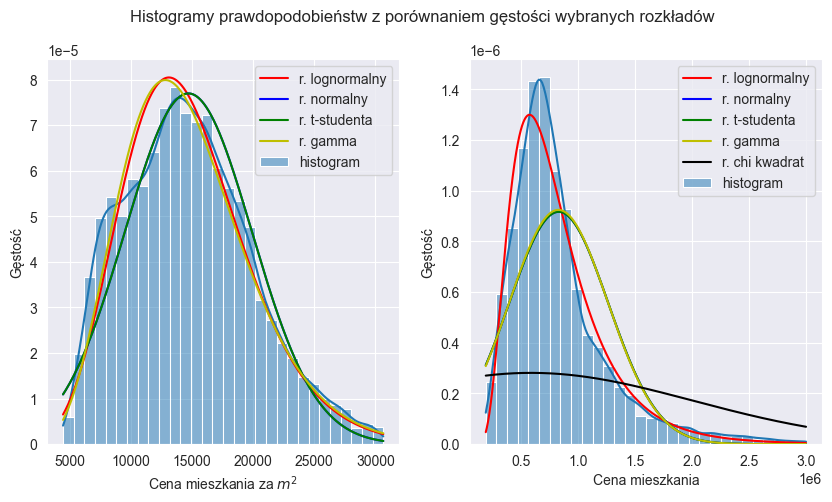

In [15]:
sorted_price_per_m2 = np.sort(price_per_m2)
sorted_price = np.sort(price)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.suptitle("Histogramy prawdopodobieństw z porównaniem gęstości wybranych rozkładów")
sns.histplot(price_per_m2, kde=True, stat="density", bins=30, ax=ax[0], label="histogram")
ax[0].plot(sorted_price_per_m2, stats.lognorm.pdf(sorted_price_per_m2, *stats.lognorm.fit(sorted_price_per_m2)), label='r. lognormalny', color='r')
ax[0].plot(sorted_price_per_m2, stats.norm.pdf(sorted_price_per_m2, *stats.norm.fit(sorted_price_per_m2)), label='r. normalny', color='b')
ax[0].plot(sorted_price_per_m2, stats.t.pdf(sorted_price_per_m2, *stats.t.fit(sorted_price_per_m2)), label='r. t-studenta', color='g')
ax[0].plot(sorted_price_per_m2, stats.gamma.pdf(sorted_price_per_m2, *stats.gamma.fit(sorted_price_per_m2)), label='r. gamma', color='y')
ax[0].set_xlabel(r"Cena mieszkania za $m^2$")
ax[0].set_ylabel("Gęstość")
ax[0].legend()

sns.histplot(price, kde=True, stat="density", bins=30, ax=ax[1], label="histogram")
ax[1].plot(sorted_price, stats.lognorm.pdf(sorted_price, *stats.lognorm.fit(price)), label='r. lognormalny', color='r')
ax[1].plot(sorted_price, stats.norm.pdf(sorted_price, *stats.norm.fit(price)), label='r. normalny', color='b')
ax[1].plot(sorted_price, stats.t.pdf(sorted_price, *stats.t.fit(price)), label='r. t-studenta', color='g')
ax[1].plot(sorted_price, stats.gamma.pdf(sorted_price, *stats.gamma.fit(price)), label='r. gamma', color='y')
ax[1].plot(sorted_price, stats.chi2.pdf(sorted_price, *stats.chi2.fit(price)), label='r. chi kwadrat', color='k')
ax[1].set_xlabel("Cena mieszkania")
ax[1].set_ylabel("Gęstość")
ax[1].legend()

plt.show()

In [16]:
y = np.log(sorted_price_per_m2)
z = stats.boxcox(sorted_price_per_m2)[0]
y = (y - np.mean(y)) / np.std(y)
z = (z - np.mean(z)) / np.std(z)

print(kstest(y, "norm").pvalue)
print(kstest(y, "t", stats.t.fit(y)).pvalue)
print(kstest(y, "norm").pvalue)
print(kstest(y, "t", stats.t.fit(z)).pvalue)

print(kstest(z, "norm").pvalue)
print(kstest(z, "t", stats.t.fit(y)).pvalue)
print(kstest(z, "norm").pvalue)
print(kstest(z, "t", stats.t.fit(z)).pvalue)

4.1015134218895106e-43
4.101806551773994e-43
4.1015134218895106e-43
4.1015988654071855e-43
8.813050108789467e-14
8.812650375269419e-14
8.813050108789467e-14
8.814437370796644e-14


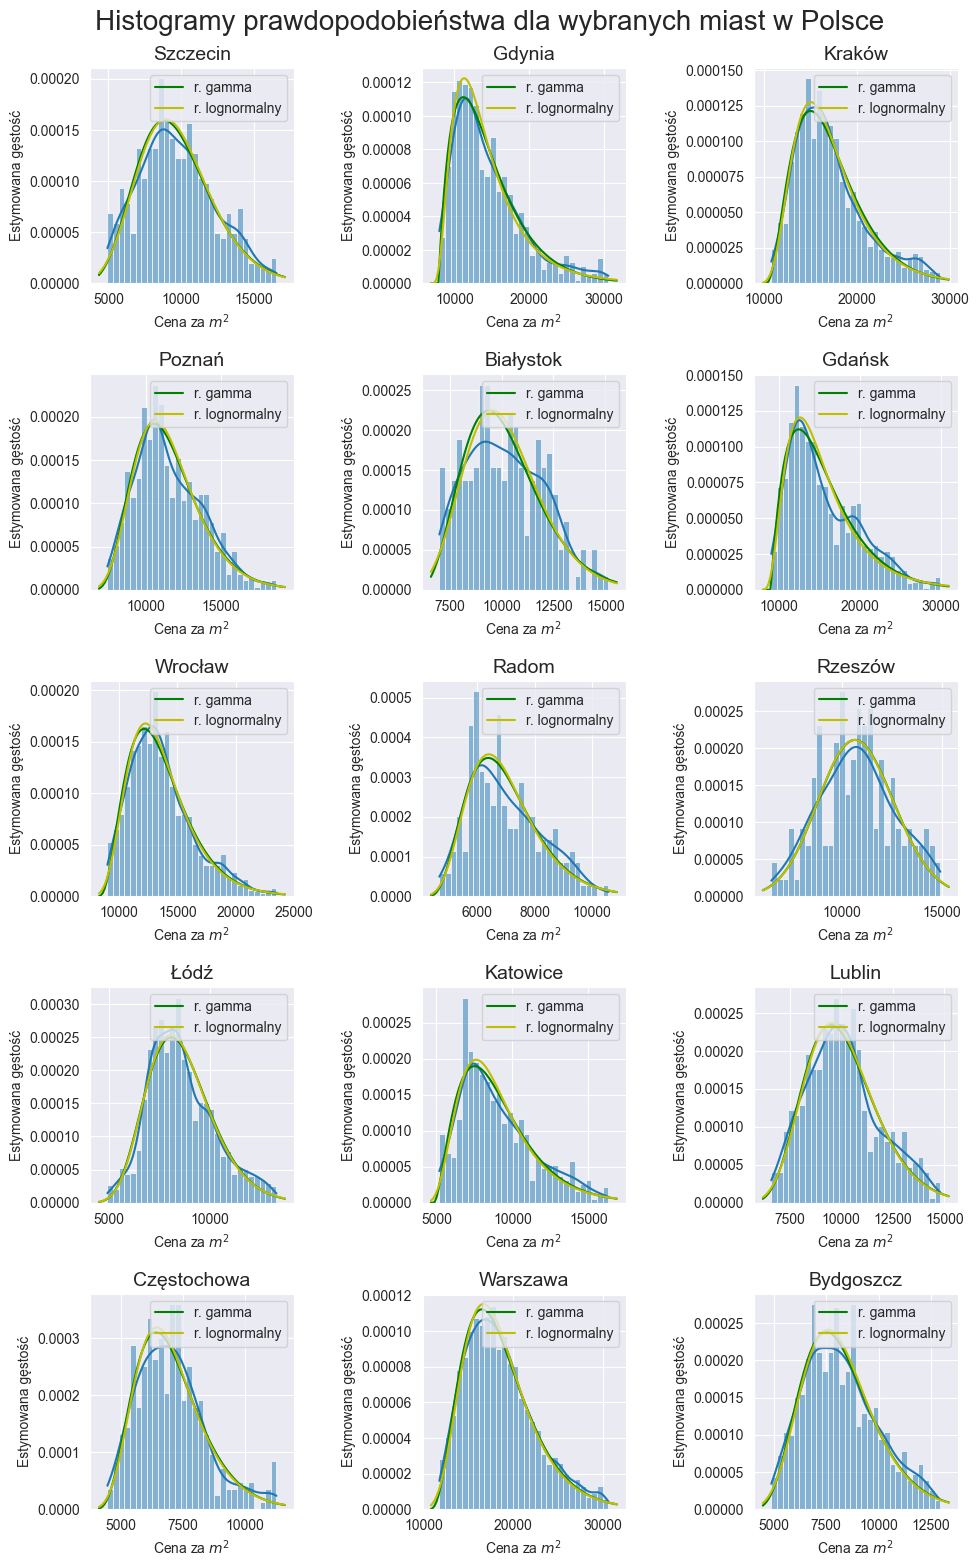

In [17]:
fig, ax = plt.subplots(5, 3, figsize=(10, 16))
fig.suptitle("Histogramy prawdopodobieństwa dla wybranych miast w Polsce", size=20)
fig.tight_layout(pad=4)
for i, city in enumerate(cities):
    x = df[df["city"] == city]["price_per_m2"]
    lognorm_params = stats.lognorm.fit(x)
    norm_params = stats.norm.fit(x)
    t_params = stats.t.fit(x)
    gamma_params = stats.gamma.fit(x)
    chi2_params = stats.chi2.fit(x)
    sns.histplot(x, kde=True, stat="density", bins=30, ax=ax[i // 3, i % 3])
    ax[i // 3, i % 3].set_title(city, size=14)
    ax[i // 3, i % 3].set_xlabel(r"Cena za $m^2$")
    ax[i // 3, i % 3].set_ylabel("Estymowana gęstość")
    xmin, xmax = ax[i // 3, i % 3].get_xlim()
    a = np.linspace(xmin, xmax, 100)
    ax[i // 3, i % 3].plot(a, stats.gamma.pdf(a, *gamma_params), label='r. gamma', color='g')
    ax[i // 3, i % 3].plot(a, stats.lognorm.pdf(a, *lognorm_params), label='r. lognormalny', color='y')
    ax[i // 3, i % 3].legend(loc='upper right')

plt.tight_layout(pad=1.5)
plt.show()

In [18]:
ks_test_distributions = {"lognorm": stats.lognorm, "norm": stats.norm, "t": stats.t, "gamma": stats.gamma, "chi2": stats.chi2}
ks_test_results_for_cities = {(distr, val): [] for distr in ks_test_distributions.keys() for val in ["Statystyka", "P-wartość"]}

for city, table in city_dataframes.items():
    city_price = table["price_per_m2"]
    for distr_name, fit_func in ks_test_distributions.items():
        ks_city_test = kstest(city_price, distr_name, fit_func.fit(city_price))
        ks_test_results_for_cities[(distr_name, "Statystyka")].append(ks_city_test.statistic)
        ks_test_results_for_cities[(distr_name, "P-wartość")].append(ks_city_test.pvalue)

ks_test_results_for_cities = pd.DataFrame(ks_test_results_for_cities, index=cities)

ks_test_results_for_cities = ks_test_results_for_cities.style.apply(lambda x: ['background-color: red' if p < alpha else '' for p in x],
                                  subset=[(distr_name, "P-wartość") for distr_name in ks_test_distributions.keys()]).set_caption("Wyniki testu Kołmogorowa-Smirnowa dla cen mieszkań w wybranych miastach w Polsce i różnych rozkładów")
display(ks_test_results_for_cities)
# print(ks_test_results_for_cities.format(precision=3).to_latex(convert_css=True))

In [19]:
ks_test_distributions = {"lognorm": stats.lognorm, "norm": stats.norm, "t": stats.t, "gamma": stats.gamma, "chi2": stats.chi2}
ks_test_results_for_cities = {(distr, val): [] for distr in ks_test_distributions.keys() for val in ["Statystyka", "P-wartość"]}

for city, table in city_dataframes.items():
    city_price = table["price"]
    city_price = city_price
    for distr_name, fit_func in ks_test_distributions.items():
        ks_city_test = kstest(city_price, distr_name, fit_func.fit(city_price))
        ks_test_results_for_cities[(distr_name, "Statystyka")].append(ks_city_test.statistic)
        ks_test_results_for_cities[(distr_name, "P-wartość")].append(ks_city_test.pvalue)

ks_test_results_for_cities = pd.DataFrame(ks_test_results_for_cities, index=cities)

ks_test_results_for_cities = ks_test_results_for_cities.style.apply(lambda x: ['background-color: red' if p < alpha else '' for p in x],
                                  subset=[(distr_name, "P-wartość") for distr_name in ks_test_distributions.keys()]).set_caption("Wyniki testu Kołmogorowa-Smirnowa dla cen mieszkań w wybranych miastach w Polsce i różnych rozkładów")
display(ks_test_results_for_cities)
# print(ks_test_results_for_cities.format(precision=3).to_latex(convert_css=True))

In [20]:
for city in cities:
    city_prices = df[df["city"] == city]["price_per_m2"]

    s, loc, scale = stats.lognorm.fit(city_prices)
    city_prices = np.log(city_prices - loc)
    mu = np.log(scale)
    sigma = s

    test = kstest(city_prices, 'norm', (mu, sigma))
    if test.pvalue >= 0.05:
        print(f"nie odrzucamy H0 dla miasta {city}")
    else:
        print(f"odrzucamy H0 dla miasta {city}")

nie odrzucamy H0 dla miasta Szczecin
nie odrzucamy H0 dla miasta Gdynia
nie odrzucamy H0 dla miasta Kraków
nie odrzucamy H0 dla miasta Poznań
nie odrzucamy H0 dla miasta Białystok
odrzucamy H0 dla miasta Gdańsk
nie odrzucamy H0 dla miasta Wrocław
nie odrzucamy H0 dla miasta Radom
nie odrzucamy H0 dla miasta Rzeszów
nie odrzucamy H0 dla miasta Łódź
nie odrzucamy H0 dla miasta Katowice
nie odrzucamy H0 dla miasta Lublin
nie odrzucamy H0 dla miasta Częstochowa
odrzucamy H0 dla miasta Warszawa
nie odrzucamy H0 dla miasta Bydgoszcz


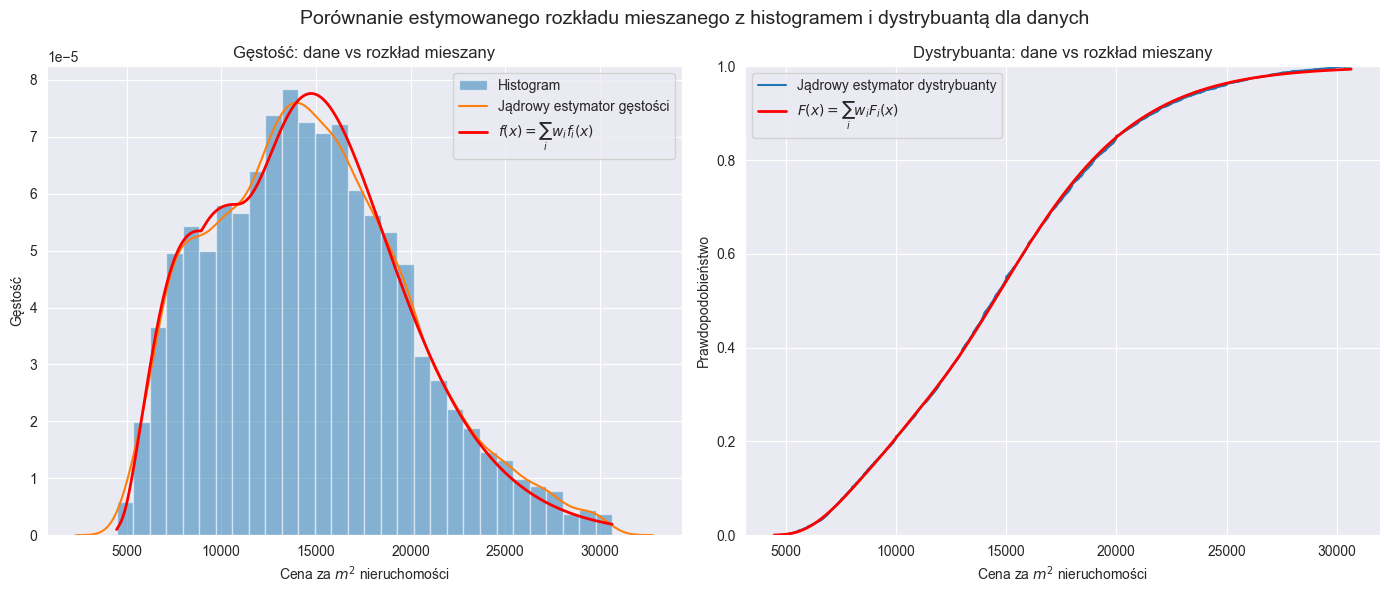

In [21]:
filtered_df = df
data = filtered_df["price_per_m2"]
sorted_data = np.sort(data)

pdf_mixture = joint_distribution(
    filtered_df,
    filtered_df["city"],
    target="price_per_m2",
    cdf=False,
    distributions={'lognorm': stats.lognorm, 'gamma': stats.gamma}
)

cdf_mixture, info = joint_distribution(
    filtered_df,
    filtered_df["city"],
    target="price_per_m2",
    cdf=True,
    return_info=True,
    distributions={'lognorm': stats.lognorm, 'gamma': stats.gamma}
)


def plot_mixture_distribution():
    global fig, axes
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    axes[0].hist(sorted_data, bins=30, density=True, alpha=0.5, label="Histogram")
    sns.kdeplot(sorted_data, ax=axes[0], label="Jądrowy estymator gęstości")

    axes[0].plot(
        sorted_data,
        pdf_mixture(sorted_data),
        color='red',
        lw=2,
        label=r'$f(x)=\sum_i w_i f_i(x)$'
    )

    axes[0].set_xlabel(r"Cena za $m^2$ nieruchomości")
    axes[0].set_ylabel("Gęstość")
    axes[0].set_title("Gęstość: dane vs rozkład mieszany")
    axes[0].legend()

    sns.ecdfplot(
        data,
        ax=axes[1],
        label="Jądrowy estymator dystrybuanty"
    )

    axes[1].plot(
        sorted_data,
        cdf_mixture(sorted_data),
        color='red',
        lw=2,
        label=r'$F(x)=\sum_i w_i F_i(x)$'
    )

    axes[1].set_xlabel(r"Cena za $m^2$ nieruchomości")
    axes[1].set_ylabel("Prawdopodobieństwo")
    axes[1].set_title("Dystrybuanta: dane vs rozkład mieszany")
    axes[1].legend()

    fig.suptitle("Porównanie estymowanego rozkładu mieszanego z histogramem i dystrybuantą dla danych", fontsize=14)
    plt.tight_layout()
    plt.show()


plot_mixture_distribution()

# print(pd.DataFrame(info.values(), index=info.keys()).drop('params', axis=1).style.map(lambda x: 'background-color: red' if x < 0.05 else '', subset=['p_value']).format('{:.3f}', subset=['p_value', 'weight']).to_latex(convert_css=True))

# result = kstest(data, cdf_mixture)
# display(pd.DataFrame({'Statystyka': result.statistic, 'P-wartość': result.pvalue}, index=['KS-Test']))
# print(pd.DataFrame({'Statystyka': result.statistic, 'P-wartość': result.pvalue}, index=['KS-Test']).to_latex())

In [22]:
result_df = pd.DataFrame(info.values(), index=info.keys())


result_df[['shape', 'loc', 'scale']] = pd.DataFrame(result_df['params'].tolist(), index=result_df.index)

result = result_df[['distribution', 'shape', 'loc', 'scale', 'weight', 'n_obs']]

result = result.round(4)

display(result)
print(result.to_latex())

,distribution,shape,loc,scale,weight,n_obs
Szczecin,lognorm,0.1976,-3402.7633,12834.5760,0.0266,528
Gdynia,lognorm,0.5971,6738.1996,6518.1160,0.0315,624
Kraków,lognorm,0.4213,8296.4939,8122.5392,0.1560,3092
Poznań,gamma,5.3766,6261.7350,975.4732,0.0360,714
Białystok,gamma,6.0344,5433.5691,780.7254,0.0108,215
Gdańsk,gamma,2.1073,8934.8925,3142.0155,0.0922,1827
Wrocław,lognorm,0.3632,6116.8596,7000.6714,0.1085,2151
Radom,gamma,4.7179,4220.7908,581.0857,0.0090,178
Rzeszów,lognorm,0.0431,-33180.1816,43903.1612,0.0078,154
Łódź,lognorm,0.2158,942.9543,7468.4268,0.0790,1565


\begin{tabular}{llrrrrr}
\toprule
 & distribution & shape & loc & scale & weight & n_obs \\
\midrule
Szczecin & lognorm & 0.197600 & -3402.763300 & 12834.576000 & 0.026600 & 528 \\
Gdynia & lognorm & 0.597100 & 6738.199600 & 6518.116000 & 0.031500 & 624 \\
Kraków & lognorm & 0.421300 & 8296.493900 & 8122.539200 & 0.156000 & 3092 \\
Poznań & gamma & 5.376600 & 6261.735000 & 975.473200 & 0.036000 & 714 \\
Białystok & gamma & 6.034400 & 5433.569100 & 780.725400 & 0.010800 & 215 \\
Gdańsk & gamma & 2.107300 & 8934.892500 & 3142.015500 & 0.092200 & 1827 \\
Wrocław & lognorm & 0.363200 & 6116.859600 & 7000.671400 & 0.108500 & 2151 \\
Radom & gamma & 4.717900 & 4220.790800 & 581.085700 & 0.009000 & 178 \\
Rzeszów & lognorm & 0.043100 & -33180.181600 & 43903.161200 & 0.007800 & 154 \\
Łódź & lognorm & 0.215800 & 942.954300 & 7468.426800 & 0.079000 & 1565 \\
Katowice & gamma & 2.770200 & 4836.732900 & 1510.084900 & 0.025800 & 511 \\
Lublin & lognorm & 0.211500 & 1756.581500 & 8143.192400 & 0.02

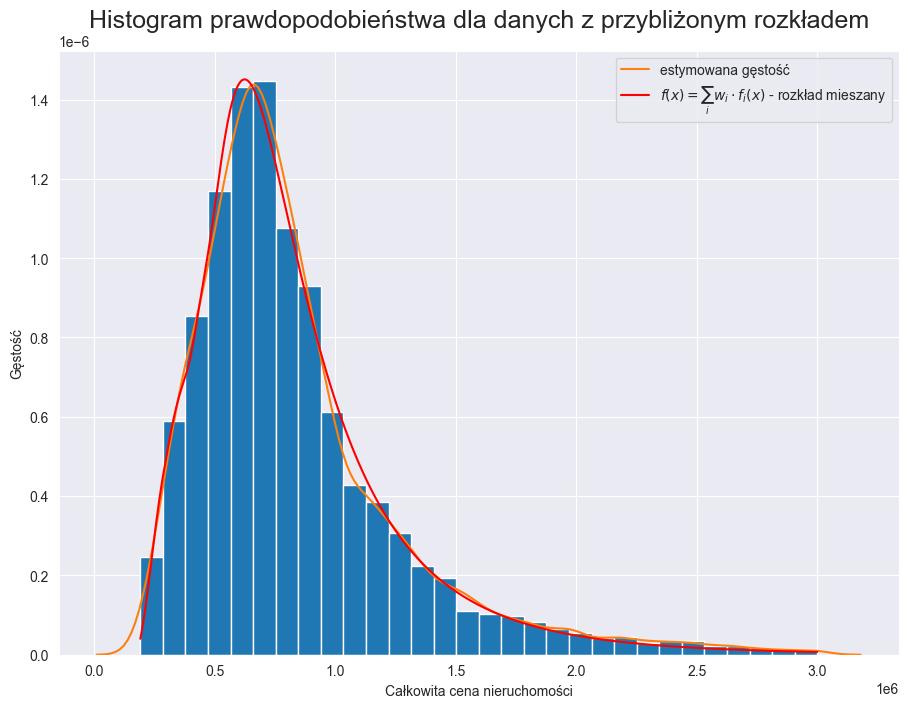

KstestResult(statistic=np.float64(0.02195900048621502), pvalue=np.float64(9.812834984659135e-09), statistic_location=np.int64(900000), statistic_sign=np.int8(1))
{'Szczecin': {'distribution': 'gamma', 'params': (np.float64(2.455620448487558), np.float64(293149.5266719973), np.float64(117644.1743930068)), 'p_value': np.float64(0.5014748436466839), 'weight': 0.026637069922308545, 'n_obs': 528}, 'Gdynia': {'distribution': 'lognorm', 'params': (np.float64(0.8940063585282471), 378869.5242705924, np.float64(353793.05136060866)), 'p_value': np.float64(0.15947837285821376), 'weight': 0.031480173544546464, 'n_obs': 624}, 'Kraków': {'distribution': 'lognorm', 'params': (np.float64(0.6265872223189936), 331384.73487050005, np.float64(502137.32296579523)), 'p_value': np.float64(7.436828166457635e-06), 'weight': 0.15598829583291293, 'n_obs': 3092}, 'Poznań': {'distribution': 'lognorm', 'params': (np.float64(0.4554552710939117), 217804.0225391855, np.float64(387086.1727830464)), 'p_value': np.float64

In [23]:
# filtered_df = df[~df["city"].isin(['Warszawa', 'Gdańsk', 'Gdynia', 'Kraków', 'Wrocław', 'Bydgoszcz'])]
filtered_df = df

sorted_price_per_m2 = np.sort(filtered_df["price"])
cumulated_dist = joint_distribution(filtered_df, filtered_df["city"], target="price", cdf=False)
cumulated_dist2, info = joint_distribution(filtered_df, filtered_df["city"], target="price", return_info=True)
plt.figure(figsize=(10, 8))
plt.hist(sorted_price_per_m2, density=True, bins=30)
sns.kdeplot(sorted_price_per_m2, label="estymowana gęstość")
plt.plot(sorted_price_per_m2, cumulated_dist(sorted_price_per_m2), label=r'$f(x)=\sum_i w_i \cdot f_i(x)$ - rozkład mieszany', color='r')
plt.xlabel(r"Całkowita cena nieruchomości")
plt.ylabel("Gęstość")
plt.legend(loc='upper right')
plt.title("Histogram prawdopodobieństwa dla danych z przybliżonym rozkładem", size=18)
plt.tight_layout(pad=4)
plt.show()

print(kstest(filtered_df["price"], cumulated_dist2))

print(info)

In [24]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/Semestr 7/Praca_inżynierska/functions.py:132: UserWarning: Kolumna "buildingMaterial" (kategoryczna) ma >40% braków → pomijam.
  warnings.warn(f'Kolumna "{column}" (kategoryczna) ma >40% braków → pomijam.')
/Users/zuzannasosnowska/PycharmProjects/UniversityProjects/Semestr 7/Praca_inżynierska/functions.py:132: UserWarning: Kolumna "condition" (kategoryczna) ma >40% braków → pomijam.
  warnings.warn(f'Kolumna "{column}" (kategoryczna) ma >40% braków → pomijam.')


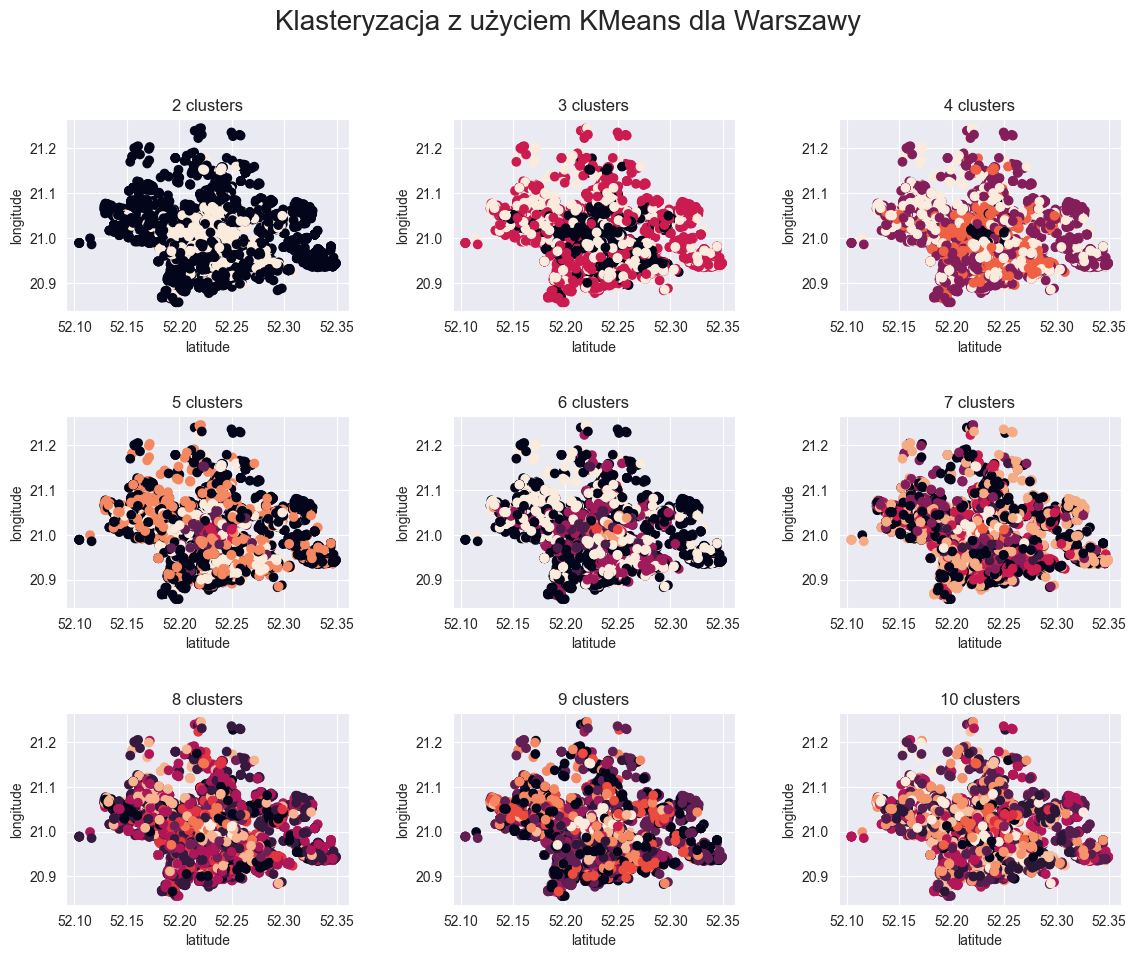

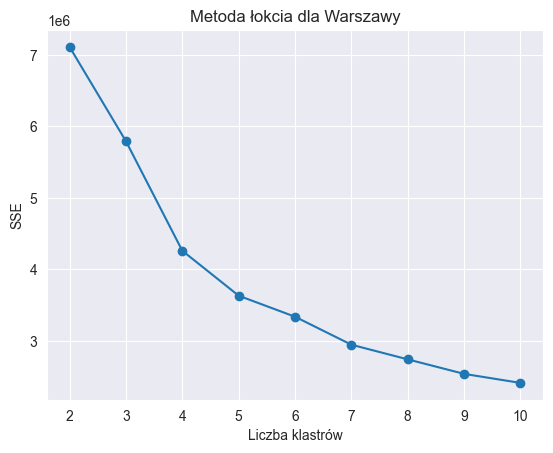

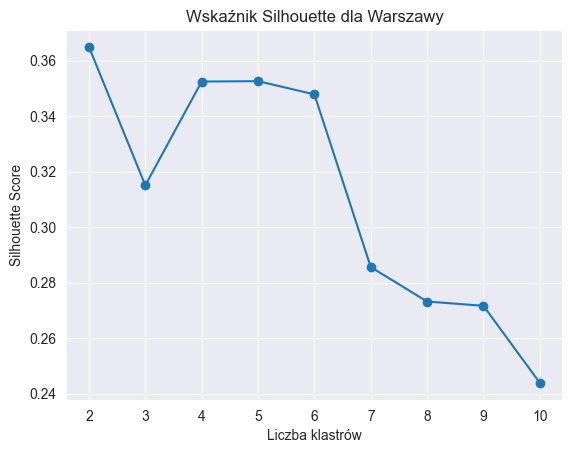

In [25]:
warsaw_df = city_dataframes['Warszawa']
warsaw_df = smart_imputer(warsaw_df)[0]
inertias = []
silhouette_scores = []

kmeans_columns = ['squareMeters', 'buildYear', 'centreDistance', 'poiCount', 'schoolDistance', 'clinicDistance', 'postOfficeDistance', 'kindergartenDistance', 'restaurantDistance', 'collegeDistance', 'pharmacyDistance', 'rooms', 'floor', 'floorCount']

n_clusters = np.arange(2, 11, 1)

fig, ax = plt.subplots(3, 3, figsize=(12, 10))
fig.suptitle("Klasteryzacja z użyciem KMeans dla Warszawy", size=20)
for i, n in enumerate(n_clusters):
    clustering = KMeans(n_clusters=n)
    X = warsaw_df[kmeans_columns]
    # X = StandardScaler().fit_transform(X)
    y = warsaw_df["price_per_m2"]
    clustering.fit(X, y)
    inertias.append(clustering.inertia_)
    silhouette_scores.append(silhouette_score(X, clustering.labels_))

    ax[i // 3, i % 3].scatter(warsaw_df["latitude"], warsaw_df["longitude"], c=clustering.labels_)
    ax[i // 3, i % 3].set_title(f"{n} clusters")
    ax[i // 3, i % 3].set_xlabel("latitude")
    ax[i // 3, i % 3].set_ylabel("longitude")

plt.tight_layout(pad=3)
plt.show()

plt.plot(n_clusters, inertias)
plt.scatter(n_clusters, inertias)
plt.xticks(n_clusters)
plt.title("Metoda łokcia dla Warszawy")
plt.xlabel("Liczba klastrów")
plt.ylabel("SSE")
plt.show()

plt.plot(n_clusters, silhouette_scores)
plt.scatter(n_clusters, silhouette_scores)
plt.xticks(n_clusters)
plt.title("Wskaźnik Silhouette dla Warszawy")
plt.xlabel("Liczba klastrów")
plt.ylabel("Silhouette Score")
plt.show()

In [26]:
def label_clusters(X, y, n_clusters):
    model = KMeans(n_clusters=n_clusters)
    model.fit(X, y)
    labels = model.labels_
    return labels

warsaw_labels = label_clusters(warsaw_df[kmeans_columns], warsaw_df["price_per_m2"], 7)

def fit_distribution(data, labels):
    max_p_values = []
    for label in np.unique(labels):
        label_data = data[labels == label]
        label_data = label_data["price_per_m2"]
        p_values = {"norm": kstest(label_data, "norm", stats.norm.fit(label_data)).pvalue,
                    "t": kstest(label_data, "t", stats.t.fit(label_data)).pvalue,
                    "gamma": kstest(label_data, "gamma", stats.gamma.fit(label_data)).pvalue,
                    "chi2": kstest(label_data, "chi2", stats.chi2.fit(label_data)).pvalue,
                    "lognorm": kstest(label_data, "lognorm", stats.lognorm.fit(label_data)).pvalue}
        max_p_values.append(max(p_values.values()))
    print(max_p_values)

chosen_cities = ["Kraków", "Gdańsk", "Wrocław", "Łódź", "Warszawa"]
for city in chosen_cities:
    print(city)
    for cluster_number in range(1, 6):
        city_df = df[df["city"] == city]
        city_labels = label_clusters(city_df[kmeans_columns], city_df["price_per_m2"], cluster_number)
        fit_distribution(city_df, city_labels)

Kraków
[np.float64(0.25650123880701337)]
[np.float64(0.20292825262790093), np.float64(0.2953018121175055)]
[np.float64(0.17691029953754112), np.float64(0.8103926960862751), np.float64(0.39982831525540796)]
[np.float64(0.5579550010924405), np.float64(0.38816590640633), np.float64(0.11373979532879697), np.float64(0.15863245803818704)]
[np.float64(0.017236657092184807), np.float64(0.33644393008112206), np.float64(0.20385219636740548), np.float64(0.5789682393702451), np.float64(0.3425120439240843)]
Gdańsk
[np.float64(0.00103057954554696)]
[np.float64(4.270106296509075e-05), np.float64(0.7744578657164961)]
[np.float64(0.0024784876814958607), np.float64(0.33688260069069853), np.float64(0.6471357080026422)]
[np.float64(0.9560685737529935), np.float64(7.58093182700235e-05), np.float64(0.6613330386521701), np.float64(0.1907701094361397)]
[np.float64(0.2166372689847471), np.float64(0.7117096632846567), np.float64(0.9560685737529935), np.float64(0.0022036525504504838), np.float64(0.01018090712157

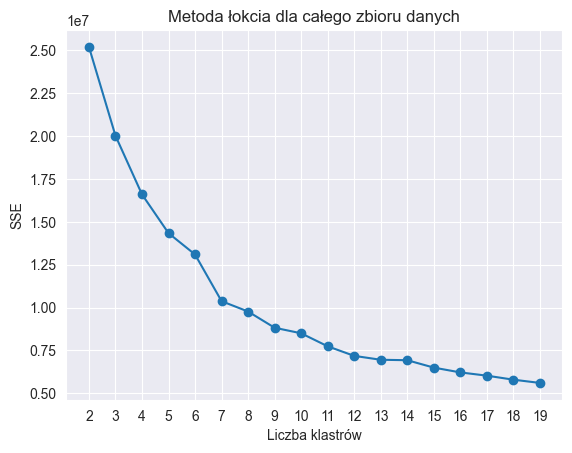

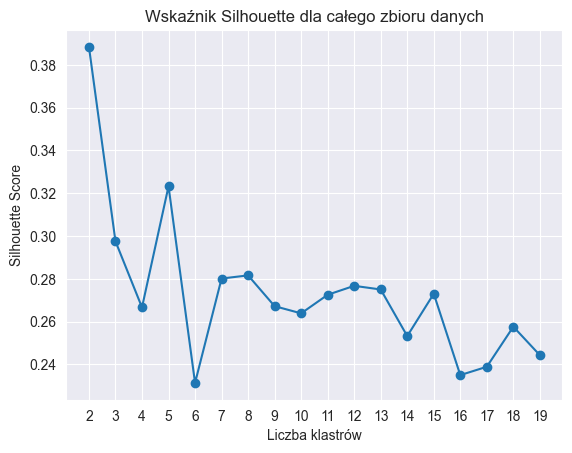

In [27]:
n_clusters = np.arange(2, 20, 1)
inertias = []
silhouette_scores = []

kmeans_columns = ['squareMeters', 'buildYear', 'centreDistance', 'poiCount', 'schoolDistance', 'clinicDistance', 'postOfficeDistance', 'kindergartenDistance', 'restaurantDistance', 'collegeDistance', 'pharmacyDistance', 'rooms', 'floor', 'floorCount']

for n_cluster in n_clusters:
    model = KMeans(n_clusters=n_cluster)
    model.fit(df[kmeans_columns], df["price_per_m2"])
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(df[kmeans_columns], model.labels_))

plt.plot(n_clusters, inertias)
plt.scatter(n_clusters, inertias)
plt.xticks(n_clusters)
plt.title("Metoda łokcia dla całego zbioru danych")
plt.xlabel("Liczba klastrów")
plt.ylabel("SSE")
plt.show()

plt.plot(n_clusters, silhouette_scores)
plt.scatter(n_clusters, silhouette_scores)
plt.xticks(n_clusters)
plt.title("Wskaźnik Silhouette dla całego zbioru danych")
plt.xlabel("Liczba klastrów")
plt.ylabel("Silhouette Score")
plt.show()

In [28]:
model = KMeans(n_clusters=5)
model.fit(df[kmeans_columns], df["price_per_m2"])

df["kmeans_labels"] = model.labels_

In [32]:
cleaned_df = df

has_columns = ['hasParkingSpace', 'hasBalcony', 'hasElevator', 'hasSecurity', 'hasStorageRoom']
for column in has_columns:
    cleaned_df[column] = cleaned_df[column].eq('yes').mul(1)

cleaned_df = cleaned_df.drop("id", axis=1)
cleaned_df = cleaned_df.drop("price_per_m2", axis=1)
cleaned_df = cleaned_df.drop("latitude", axis=1)
cleaned_df = cleaned_df.drop("longitude", axis=1)

cleaned_df = pd.get_dummies(
    cleaned_df,
    columns=["city", "type", "ownership", "buildingMaterial", "condition"],
    dtype=int
)

cleaned_df

,squareMeters,rooms,floor,floorCount,buildYear,centreDistance,poiCount,schoolDistance,clinicDistance,postOfficeDistance,...,type_apartmentBuilding,type_blockOfFlats,type_tenement,ownership_condominium,ownership_cooperative,ownership_udział,buildingMaterial_brick,buildingMaterial_concreteSlab,condition_low,condition_premium
0,47.00,2.0,6.0,12.0,1981.0,0.79,67.0,0.288,0.285,0.268,...,0,1,0,1,0,0,0,1,0,0
1,88.22,3.0,1.0,2.0,2000.0,4.09,0.0,0.509,1.039,0.998,...,1,0,0,1,0,0,1,0,0,1
2,117.00,5.0,4.0,4.0,1993.0,2.19,10.0,0.216,0.611,0.743,...,1,0,0,0,0,1,1,0,0,1
3,33.31,1.0,1.0,4.0,1963.0,1.93,39.0,0.073,0.326,0.284,...,0,1,0,0,1,0,1,0,0,0
4,56.00,3.0,7.0,7.0,2018.0,2.68,10.0,0.268,0.771,0.676,...,0,1,0,1,0,0,1,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21496,54.00,3.0,4.0,4.0,1993.0,3.01,16.0,0.325,0.599,0.201,...,0,1,0,1,0,0,0,0,0,0
21497,98.00,3.0,3.0,2.0,1925.0,0.59,49.0,0.113,0.226,0.225,...,0,0,1,1,0,0,1,0,0,0
21498,108.96,5.0,2.0,4.0,1889.0,1.08,28.0,0.281,0.792,0.233,...,0,0,1,1,0,0,1,0,0,0
21499,50.12,2.0,1.0,1.0,1993.0,0.88,42.0,0.174,0.496,0.388,...,0,1,0,1,0,0,1,0,0,0


In [33]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

y = cleaned_df["price"]
X = cleaned_df.drop("price", axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(model.score(X_test, y_test))

coeffs = [model.intercept_] + list(model.coef_)

pd.DataFrame({"coeff": [coeff for coeff in coeffs]}, index=["a_0"] + list(X.columns))

0.7784934474959208


,coeff
a_0,-2.849689e+06
squareMeters,1.456591e+04
rooms,-2.817193e+04
floor,1.169419e+03
floorCount,9.089671e+02
buildYear,1.402589e+03
centreDistance,-1.695253e+04
poiCount,1.461162e+03
schoolDistance,-3.334595e+03
clinicDistance,-5.741056e+02
